# 13 — The hardware experiments: what each program does

The programs built for H2, drawn as a schematic (stages) and as the circuit that is compiled.
All of them passed the H2-1SC syntax checker on 2026-10-14 (submitted through aqora as
organisation `q_sq`): H2 accepts them as written. Nothing has been executed yet.

**Source:** programs in `results/hardware/programs/` and `results/hardware/calibration_programs/`
(built by `hardware.cli build` / `calib-build`, H2 env); diagrams from `qec_timing.diagrams`,
which uses the same check orders as `hardware.qir`; checks in `results/hardware/syntax_checks.json`.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
from qec_timing import diagrams as D
from qec_timing.codes.surface import RotatedSurfaceCode
HW = R / "hardware"
sc = json.loads((HW / "syntax_checks.json").read_text())
print(f"{'program':<16}{'H2-1SC status':<16}{'registers':>10}{'bits':>7}")
for r in sc["rows"]:
    if r["job_id"]:
        o = r["output"][0]
        print(f"{r['program']:<16}{r['status']:<16}{o['registers']:>10}{o['bits']:>7}")

program         H2-1SC status    registers   bits
d3_X_r2_p0.05   COMPLETED               17   1088
readout         COMPLETED               16   1024
idle_X_L0       COMPLETED                9    576
idle_X_L16      COMPLETED                9    576
idle_X_L2       COMPLETED                9    576
idle_X_L32      COMPLETED                9    576
idle_X_L4       COMPLETED                9    576
idle_X_L64      COMPLETED                9    576
idle_X_L8       COMPLETED                9    576
idle_Z_L0       COMPLETED                9    576
idle_Z_L16      COMPLETED                9    576
idle_Z_L2       COMPLETED                9    576
idle_Z_L32      COMPLETED                9    576
idle_Z_L4       COMPLETED                9    576
idle_Z_L64      COMPLETED                9    576
idle_Z_L8       COMPLETED                9    576


## Memory experiment (pipeline check; t_R from the job's duration)

d = 3 rotated surface code, X basis, 2 rounds. Nine data qubits and **one** ancilla, reused for
every check (measure, then reset), so the four X checks run one after another. Before each
round every data qubit gets a Z with probability p = 0.05 from a seeded in-program RNG (the
artificial noise; set p = 0 for device noise only). Outputs: s{round}{check} syndrome bits and
m{i} final X readouts.

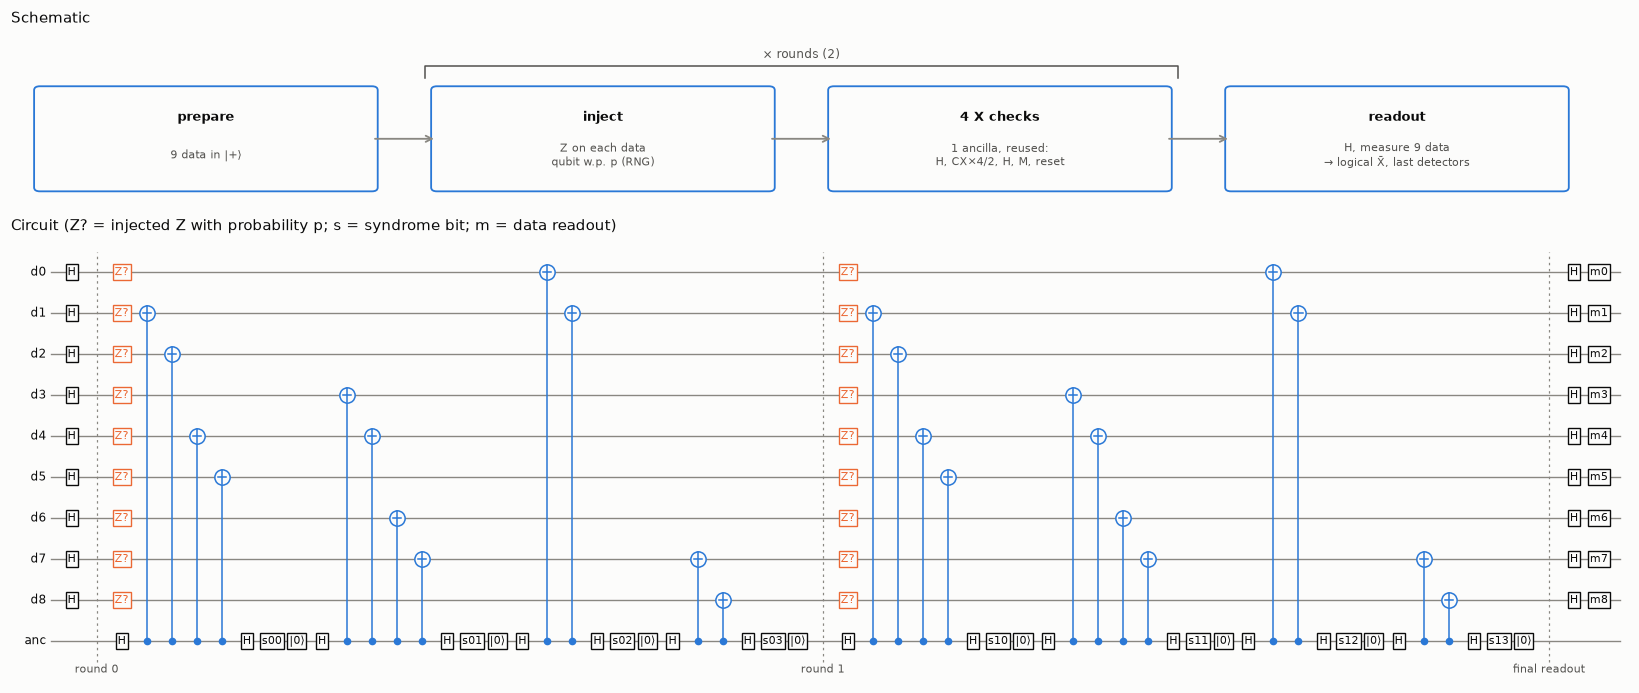

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(15, 6.4), gridspec_kw={"height_ratios": [1, 2.6]})
D.schematic(axes[0], [("prepare", "9 data in |+⟩"),
                      ("inject", "Z on each data\nqubit w.p. p (RNG)"),
                      ("4 X checks", "1 ancilla, reused:\nH, CX×4/2, H, M, reset"),
                      ("readout", "H, measure 9 data\n→ logical X̄, last detectors")],
            "Schematic", repeat=(1, 2, "× rounds (2)"))
D.draw(axes[1], D.memory_circuit(RotatedSurfaceCode(3), "X", 2, True),
       "Circuit (Z? = injected Z with probability p; s = syndrome bit; m = data readout)")
fig.tight_layout()
P.save(fig, "13_hardware_experiments_1")

## Readout (T2): p_meas0 and p_meas1

8 qubits are measured straight after preparation in |0⟩; 8 more are flipped to |1⟩ first. The
fraction of 1s on the first half is p_meas0, of 0s on the second half p_meas1.

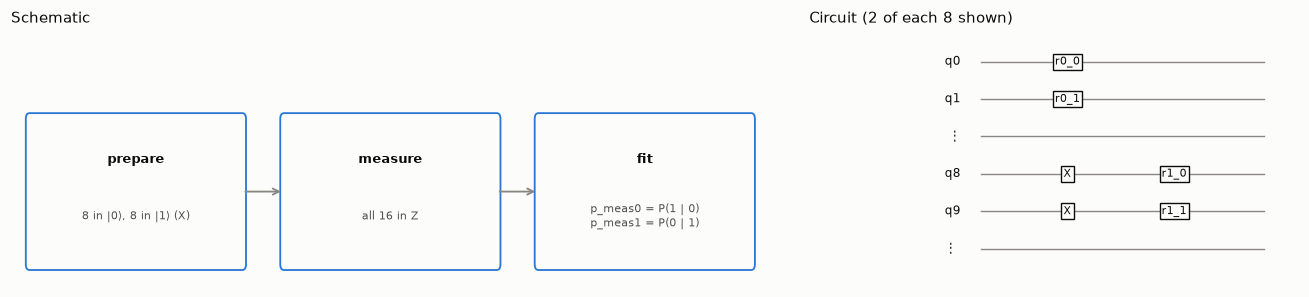

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), gridspec_kw={"width_ratios": [1.6, 1]})
D.schematic(axes[0], [("prepare", "8 in |0⟩, 8 in |1⟩ (X)"), ("measure", "all 16 in Z"),
                      ("fit", "p_meas0 = P(1 | 0)\np_meas1 = P(0 | 1)")], "Schematic")
D.draw(axes[1], D.readout_circuit(), "Circuit (2 of each 8 shown)")
fig.tight_layout()
P.save(fig, "13_hardware_experiments_2")

## Idle (T3 Z basis, T4 X basis): the idle law, without a delay instruction

Guppy has no delay, so 8 target qubits wait while 2 spectators run L layers of H, measure,
reset (L = 0, 2, 4, …, 64). A Z on each target, conditioned on the parity of all spectator
outcomes (feed-forward), forces the targets' measurement after the layers; the analysis undoes
it. X basis (targets in |+⟩) sees dephasing and gives γ and c per layer; Z basis (targets in
|0⟩) should stay flat if idling is Z only. Idle time is counted in layers: seconds need the
layer's duration from the job.

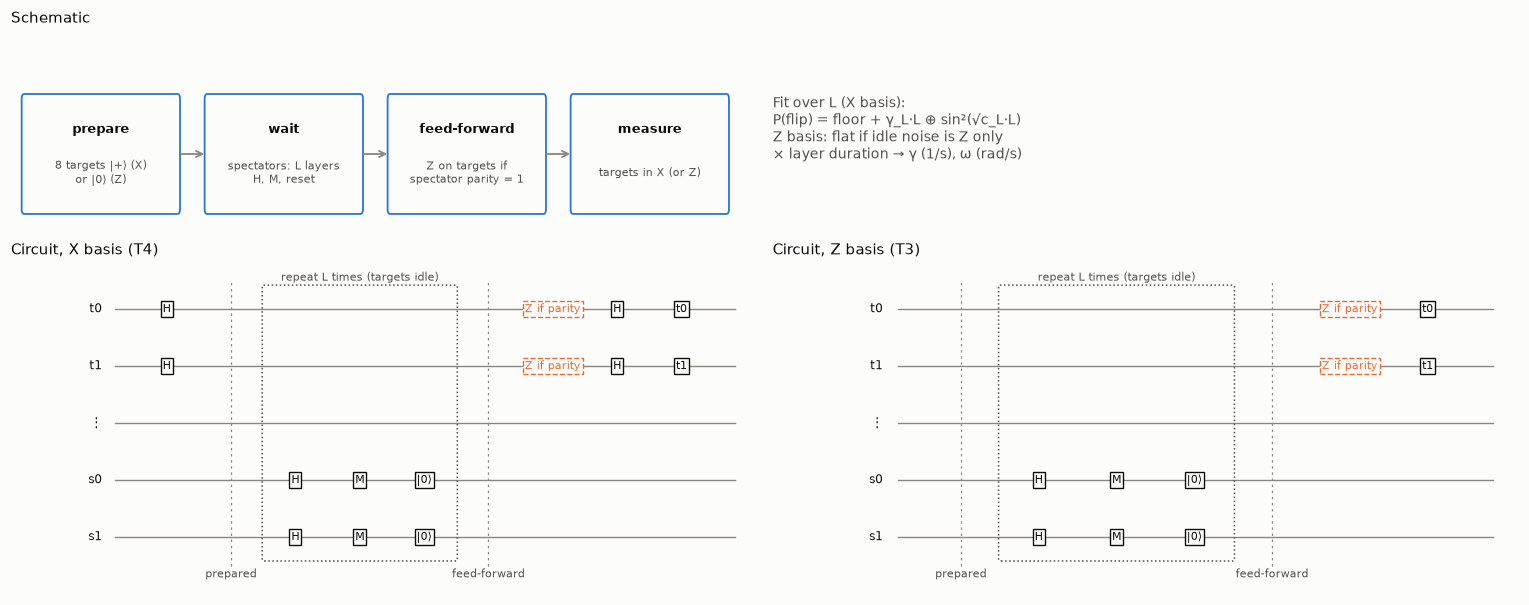

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 5.6), gridspec_kw={"height_ratios": [1, 1.7]})
D.schematic(axes[0, 0], [("prepare", "8 targets |+⟩ (X)\nor |0⟩ (Z)"),
                         ("wait", "spectators: L layers\nH, M, reset"),
                         ("feed-forward", "Z on targets if\nspectator parity = 1"),
                         ("measure", "targets in X (or Z)")], "Schematic")
axes[0, 1].axis("off")
axes[0, 1].text(0.0, 0.5, "Fit over L (X basis):\nP(flip) = floor + γ_L·L ⊕ sin²(√c_L·L)\n"
                "Z basis: flat if idle noise is Z only\n× layer duration → γ (1/s), ω (rad/s)",
                fontsize=9, color=P.INK_2, va="center")
D.draw(axes[1, 0], D.idle_circuit("X"), "Circuit, X basis (T4)")
D.draw(axes[1, 1], D.idle_circuit("Z"), "Circuit, Z basis (T3)")
fig.tight_layout()
P.save(fig, "13_hardware_experiments_3")

**What passing the syntax checker does and does not establish.**
- *Measured:* H2 accepts every program as written: instructions, qubit counts, feed-forward,
  in-program RNG and output registers.
- *Not established:* any physics (no noise, placeholder zeros), timing (no duration report),
  whether the compiler keeps the spectator layers as real idle time, and the HQC price (not
  returned through aqora). These need the H2-1E emulator, then the device.